# 轨迹跟踪 RMSE、最大速度与可视化

按 bag 中 /rosout 的 Ref: ... => TRAJ / Ref: TRAJ => ... 切换确定每次实际跟踪窗口，用 /flygripper/geometric_controller/data 同一消息的参考值和当前值计算逐次 RMSE。最大速度为窗口内采样到的三轴速度模长最大值，分别列出参考速度和实际速度。

运行下面的代码单元格时，每生成一张 XYZ 或 XY 图就会直接显示在 Notebook 中，并同时保存 PNG、CSV 和 JSON。若当前 Jupyter 内核缺少依赖，先运行 %pip install rosbags numpy matplotlib。

In [25]:
from pathlib import Path
import sys
import importlib
from IPython.display import Image, Markdown, display

# 在仓库根目录或 scripts/ 目录启动 Jupyter 都能找到配套分析脚本。
script_path = next(
    (candidate for directory in (Path.cwd(), *Path.cwd().parents)
     for candidate in (directory / "scripts" / "analyze_trajectory_tracking.py",
                       directory / "analyze_trajectory_tracking.py")
     if candidate.is_file()),
    None,
)
if script_path is None:
    raise FileNotFoundError("找不到 scripts/analyze_trajectory_tracking.py；请从 HIARM 仓库启动 Jupyter")
sys.path.insert(0, str(script_path.parent))
import analyze_trajectory_tracking as tracking
tracking = importlib.reload(tracking)

print(f"分析模块：{script_path}")

分析模块：/Users/lzf/Documents/wfzf/HIARM/scripts/analyze_trajectory_tracking.py


In [26]:
BAG = Path("/Users/lzf/Documents/wfzf/8/2026-10-23-11-18-10.bag")
OUTPUT = BAG.with_name(BAG.stem + "_tracking")
NAMESPACE = "flygripper"

if not BAG.is_file():
    raise FileNotFoundError(BAG)
print(f"Bag：{BAG}")
print(f"输出目录：{OUTPUT}")

Bag：/Users/lzf/Documents/wfzf/8/2026-10-23-11-18-10.bag
输出目录：/Users/lzf/Documents/wfzf/8/2026-10-23-11-18-10_tracking


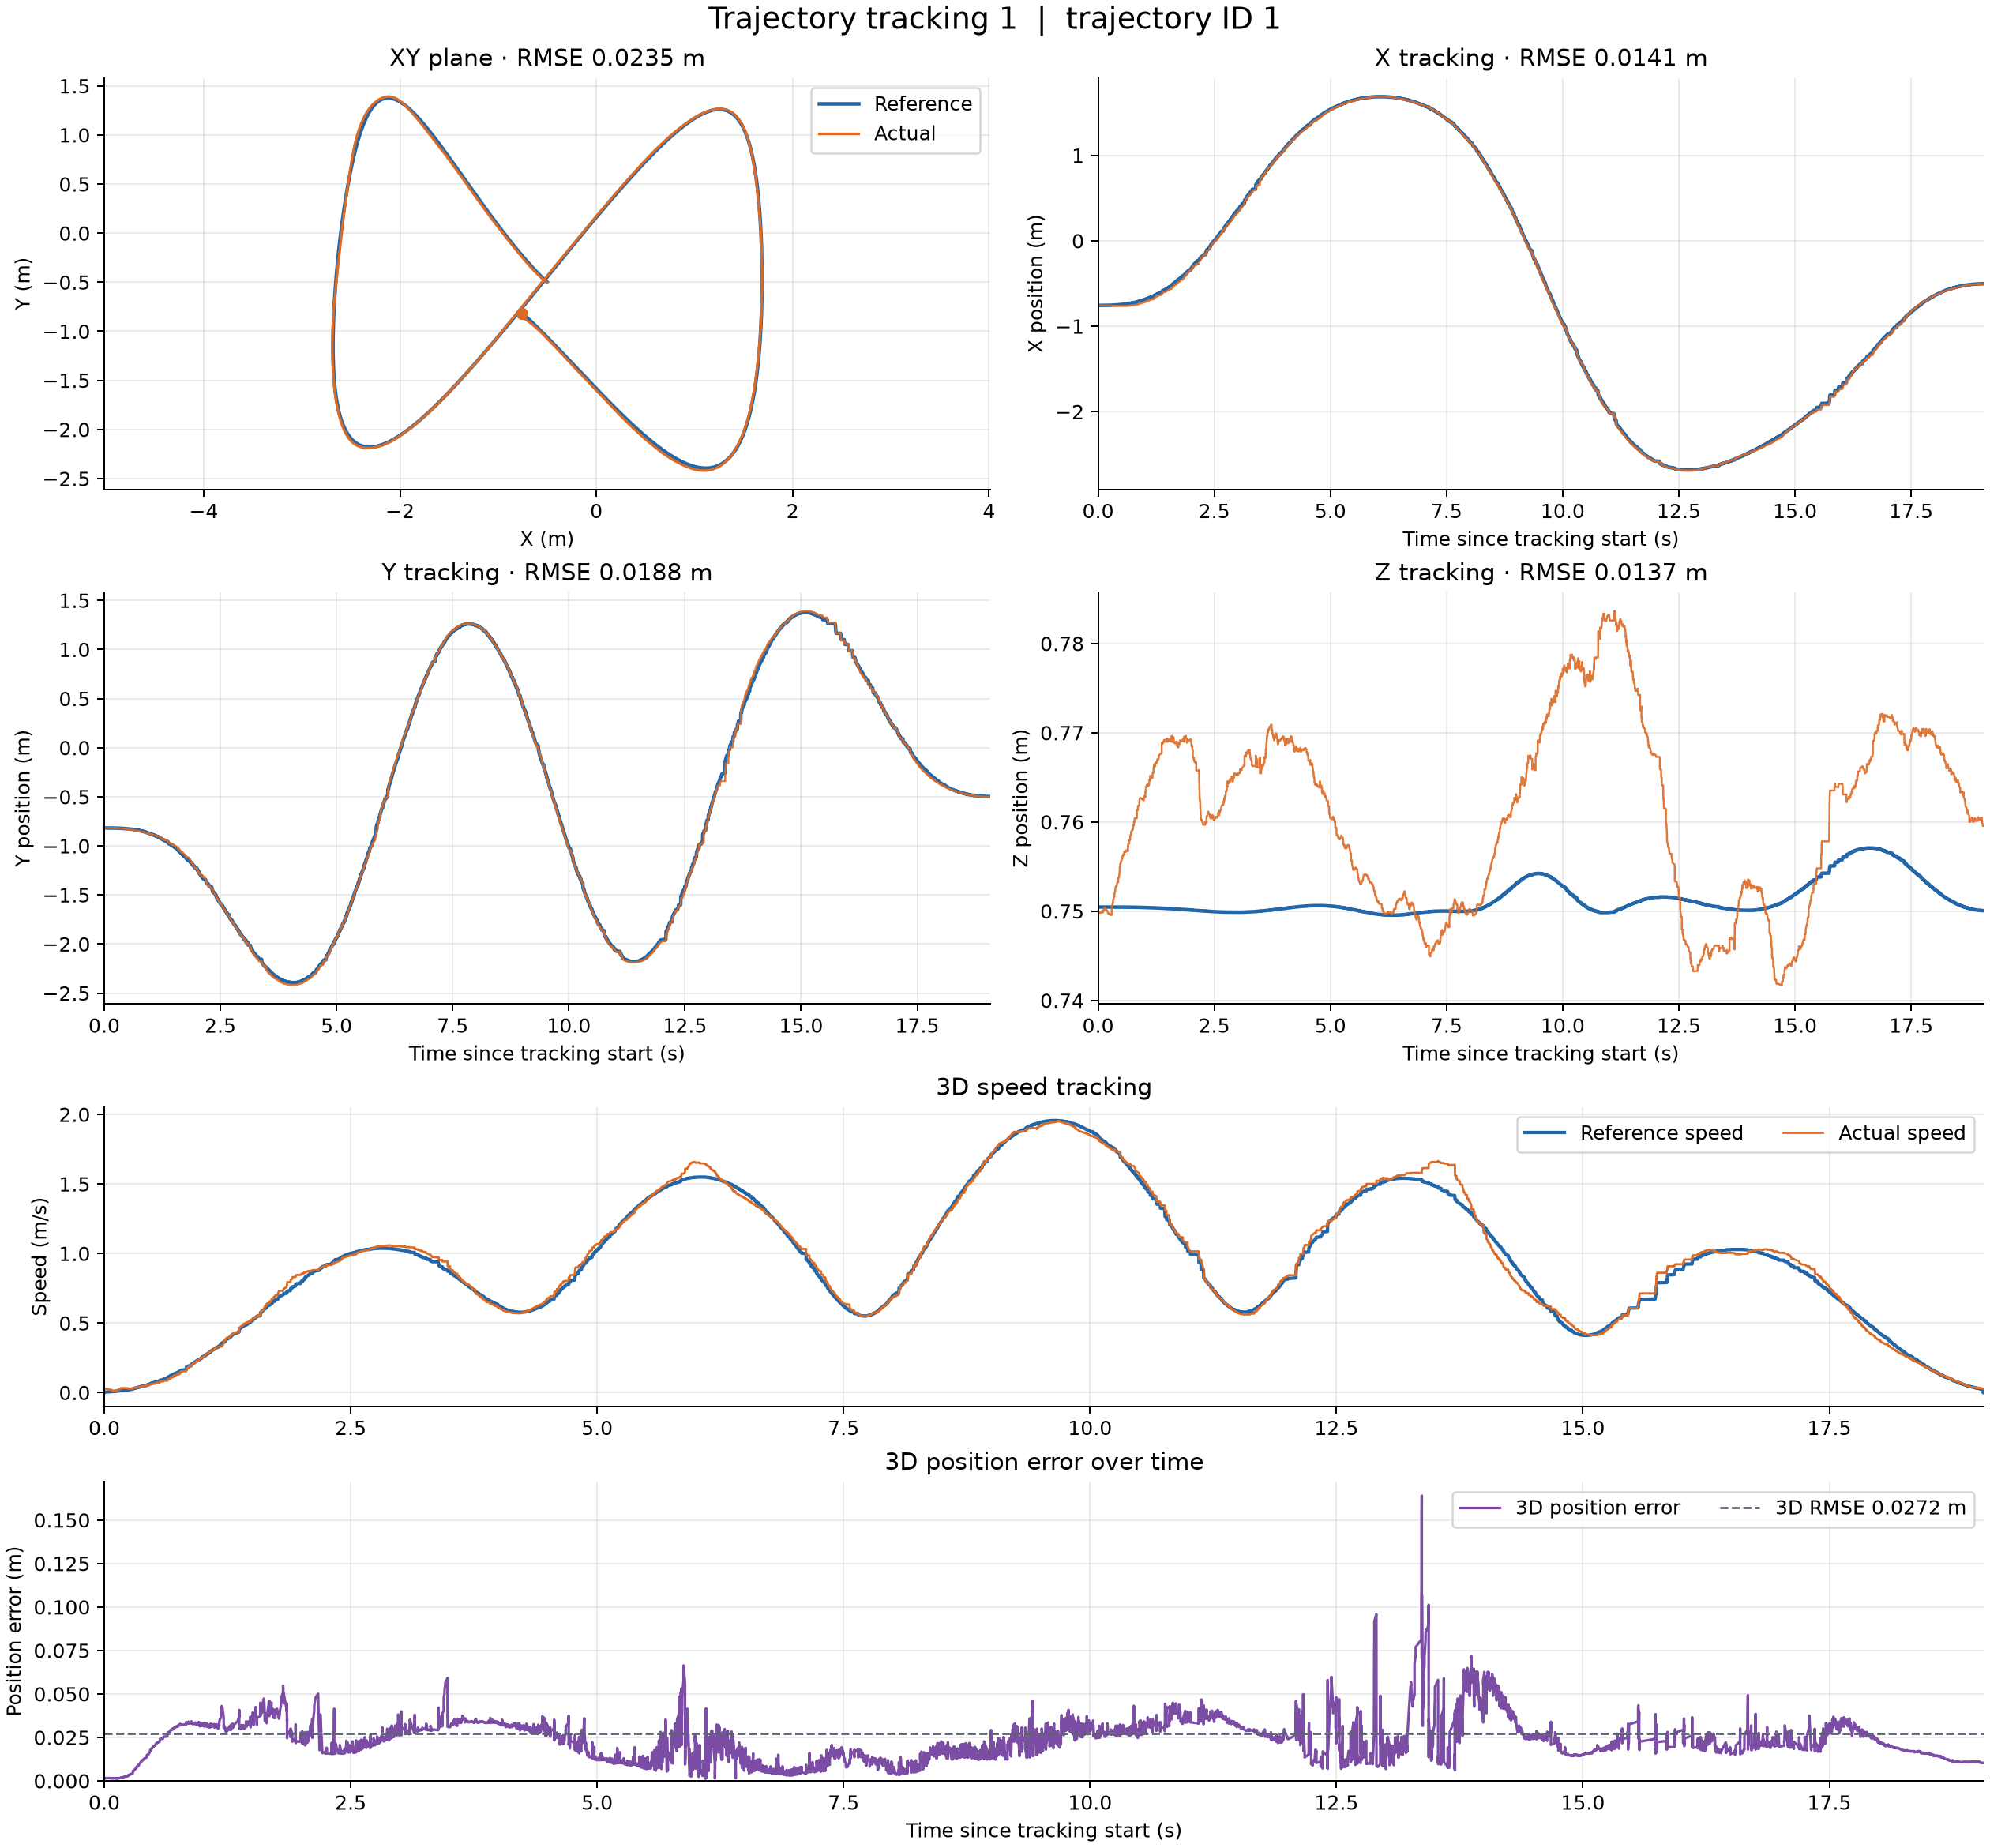

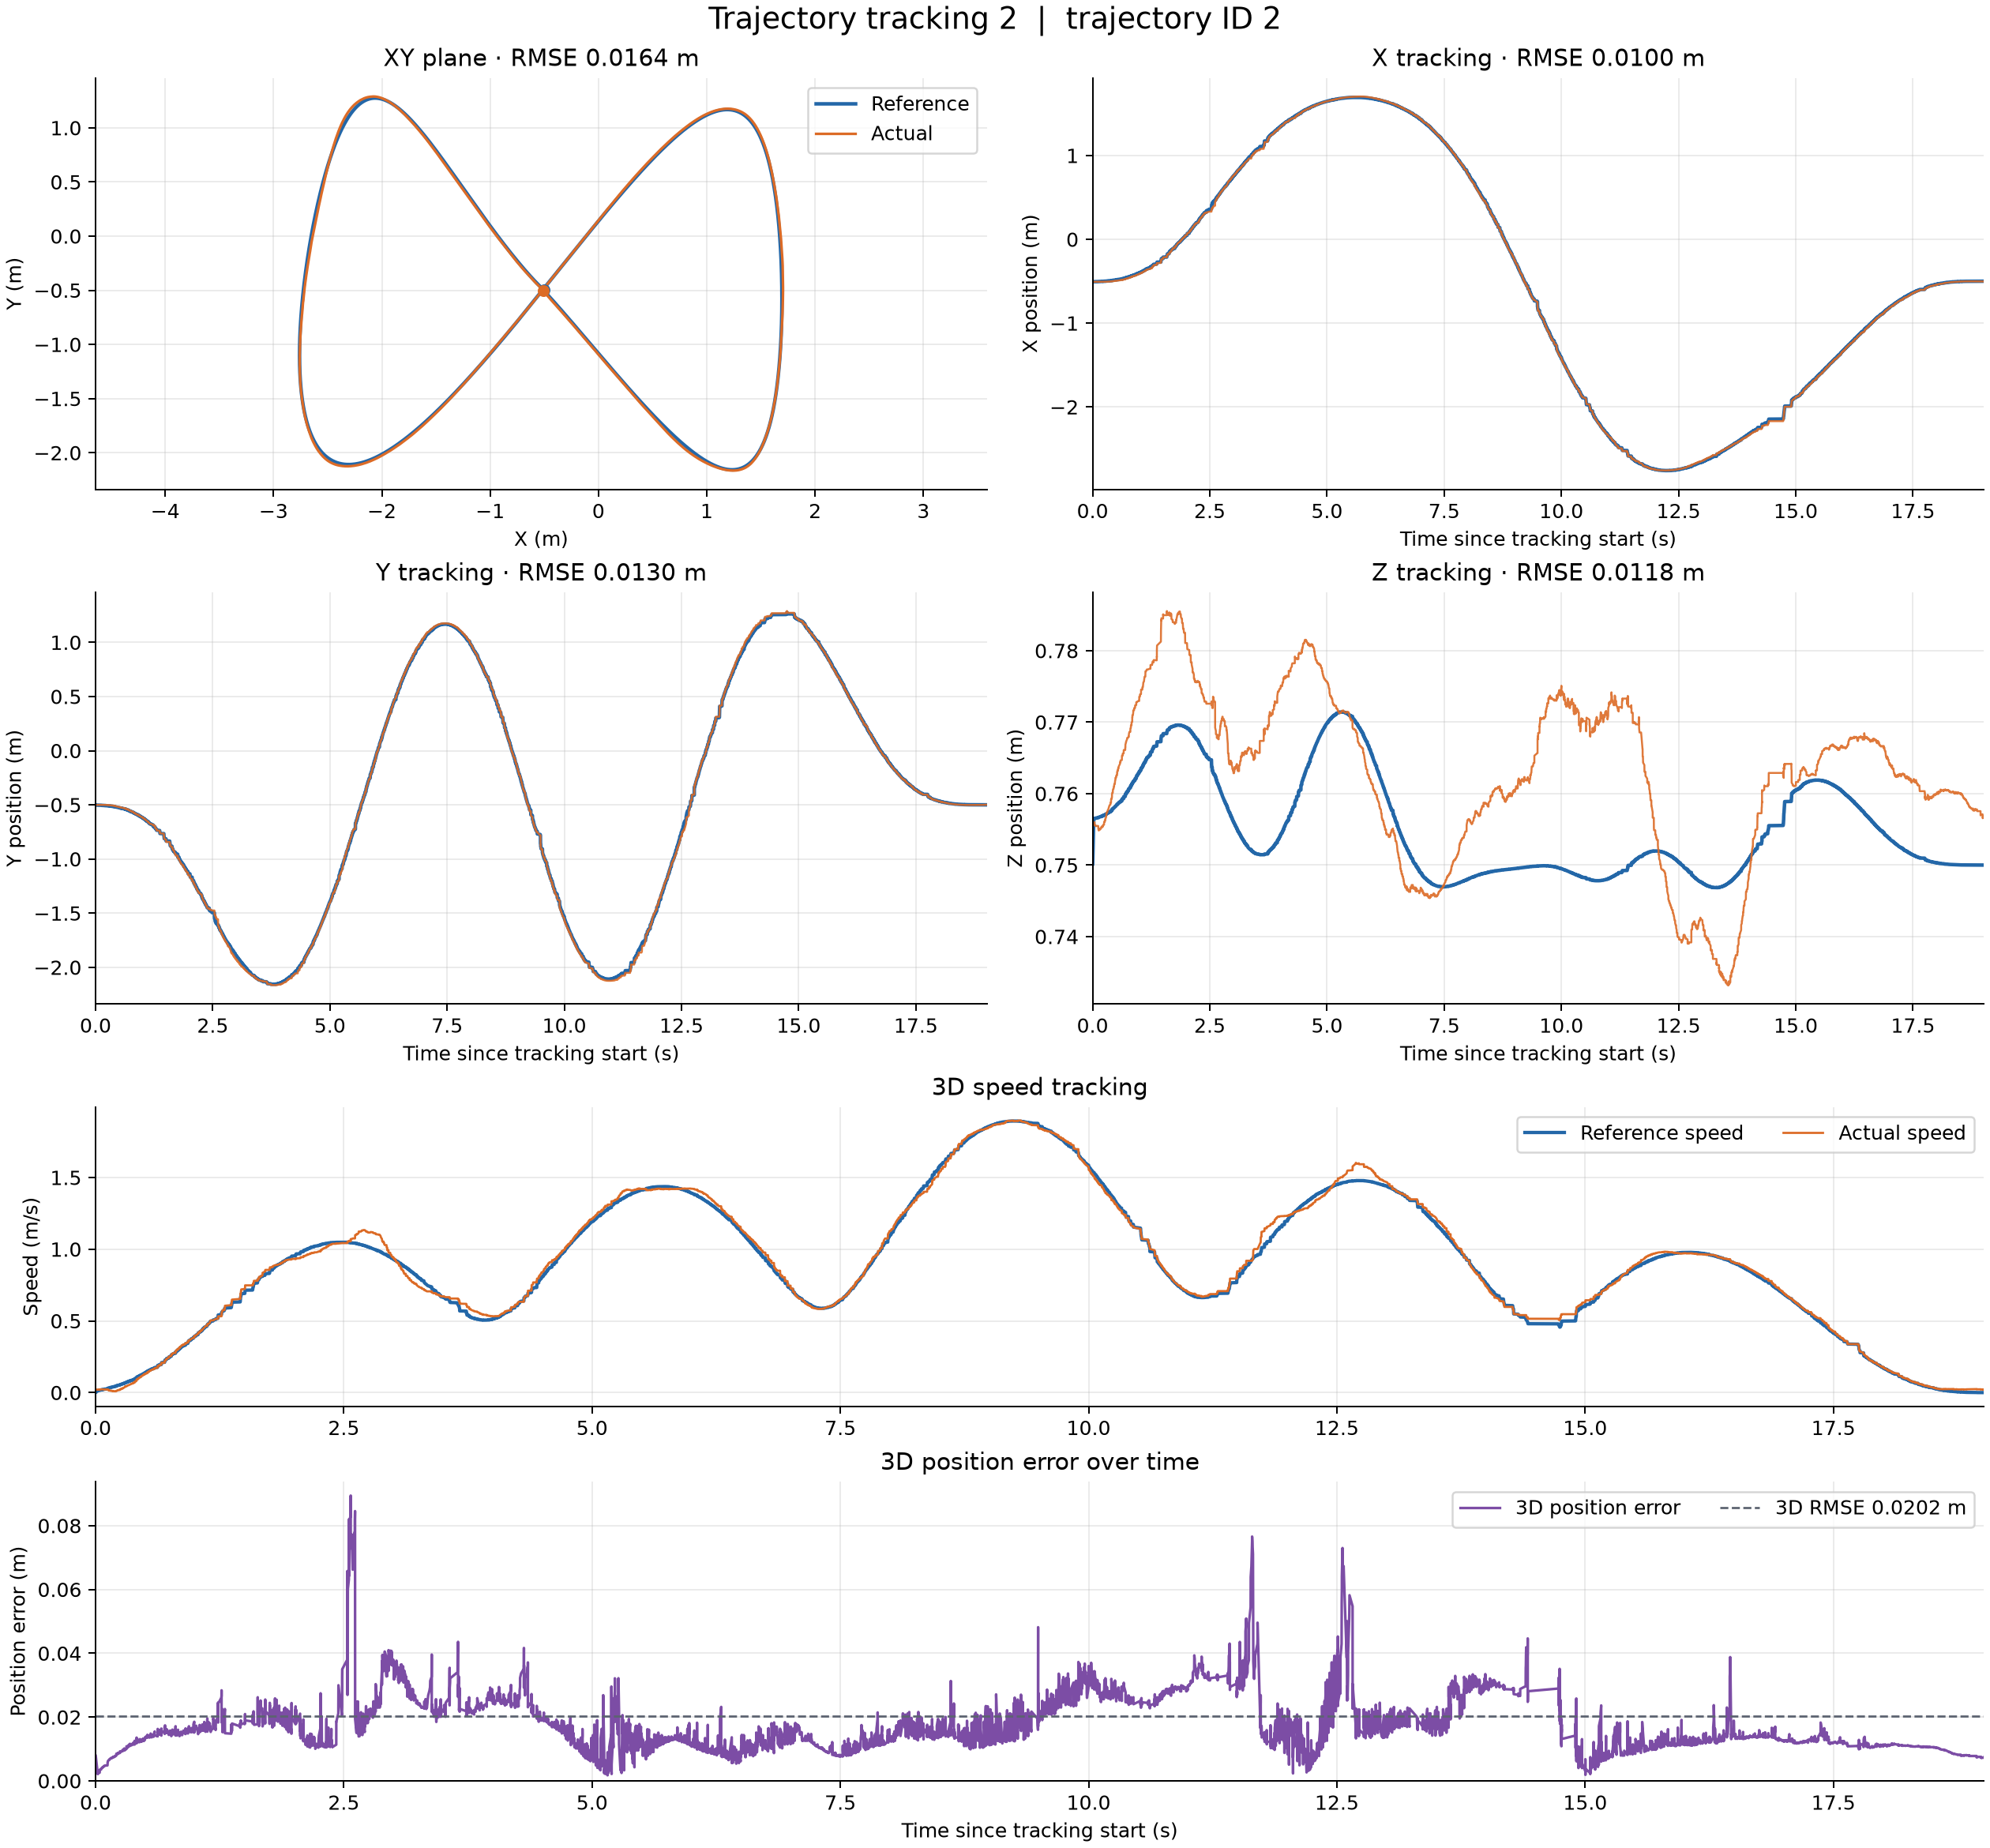

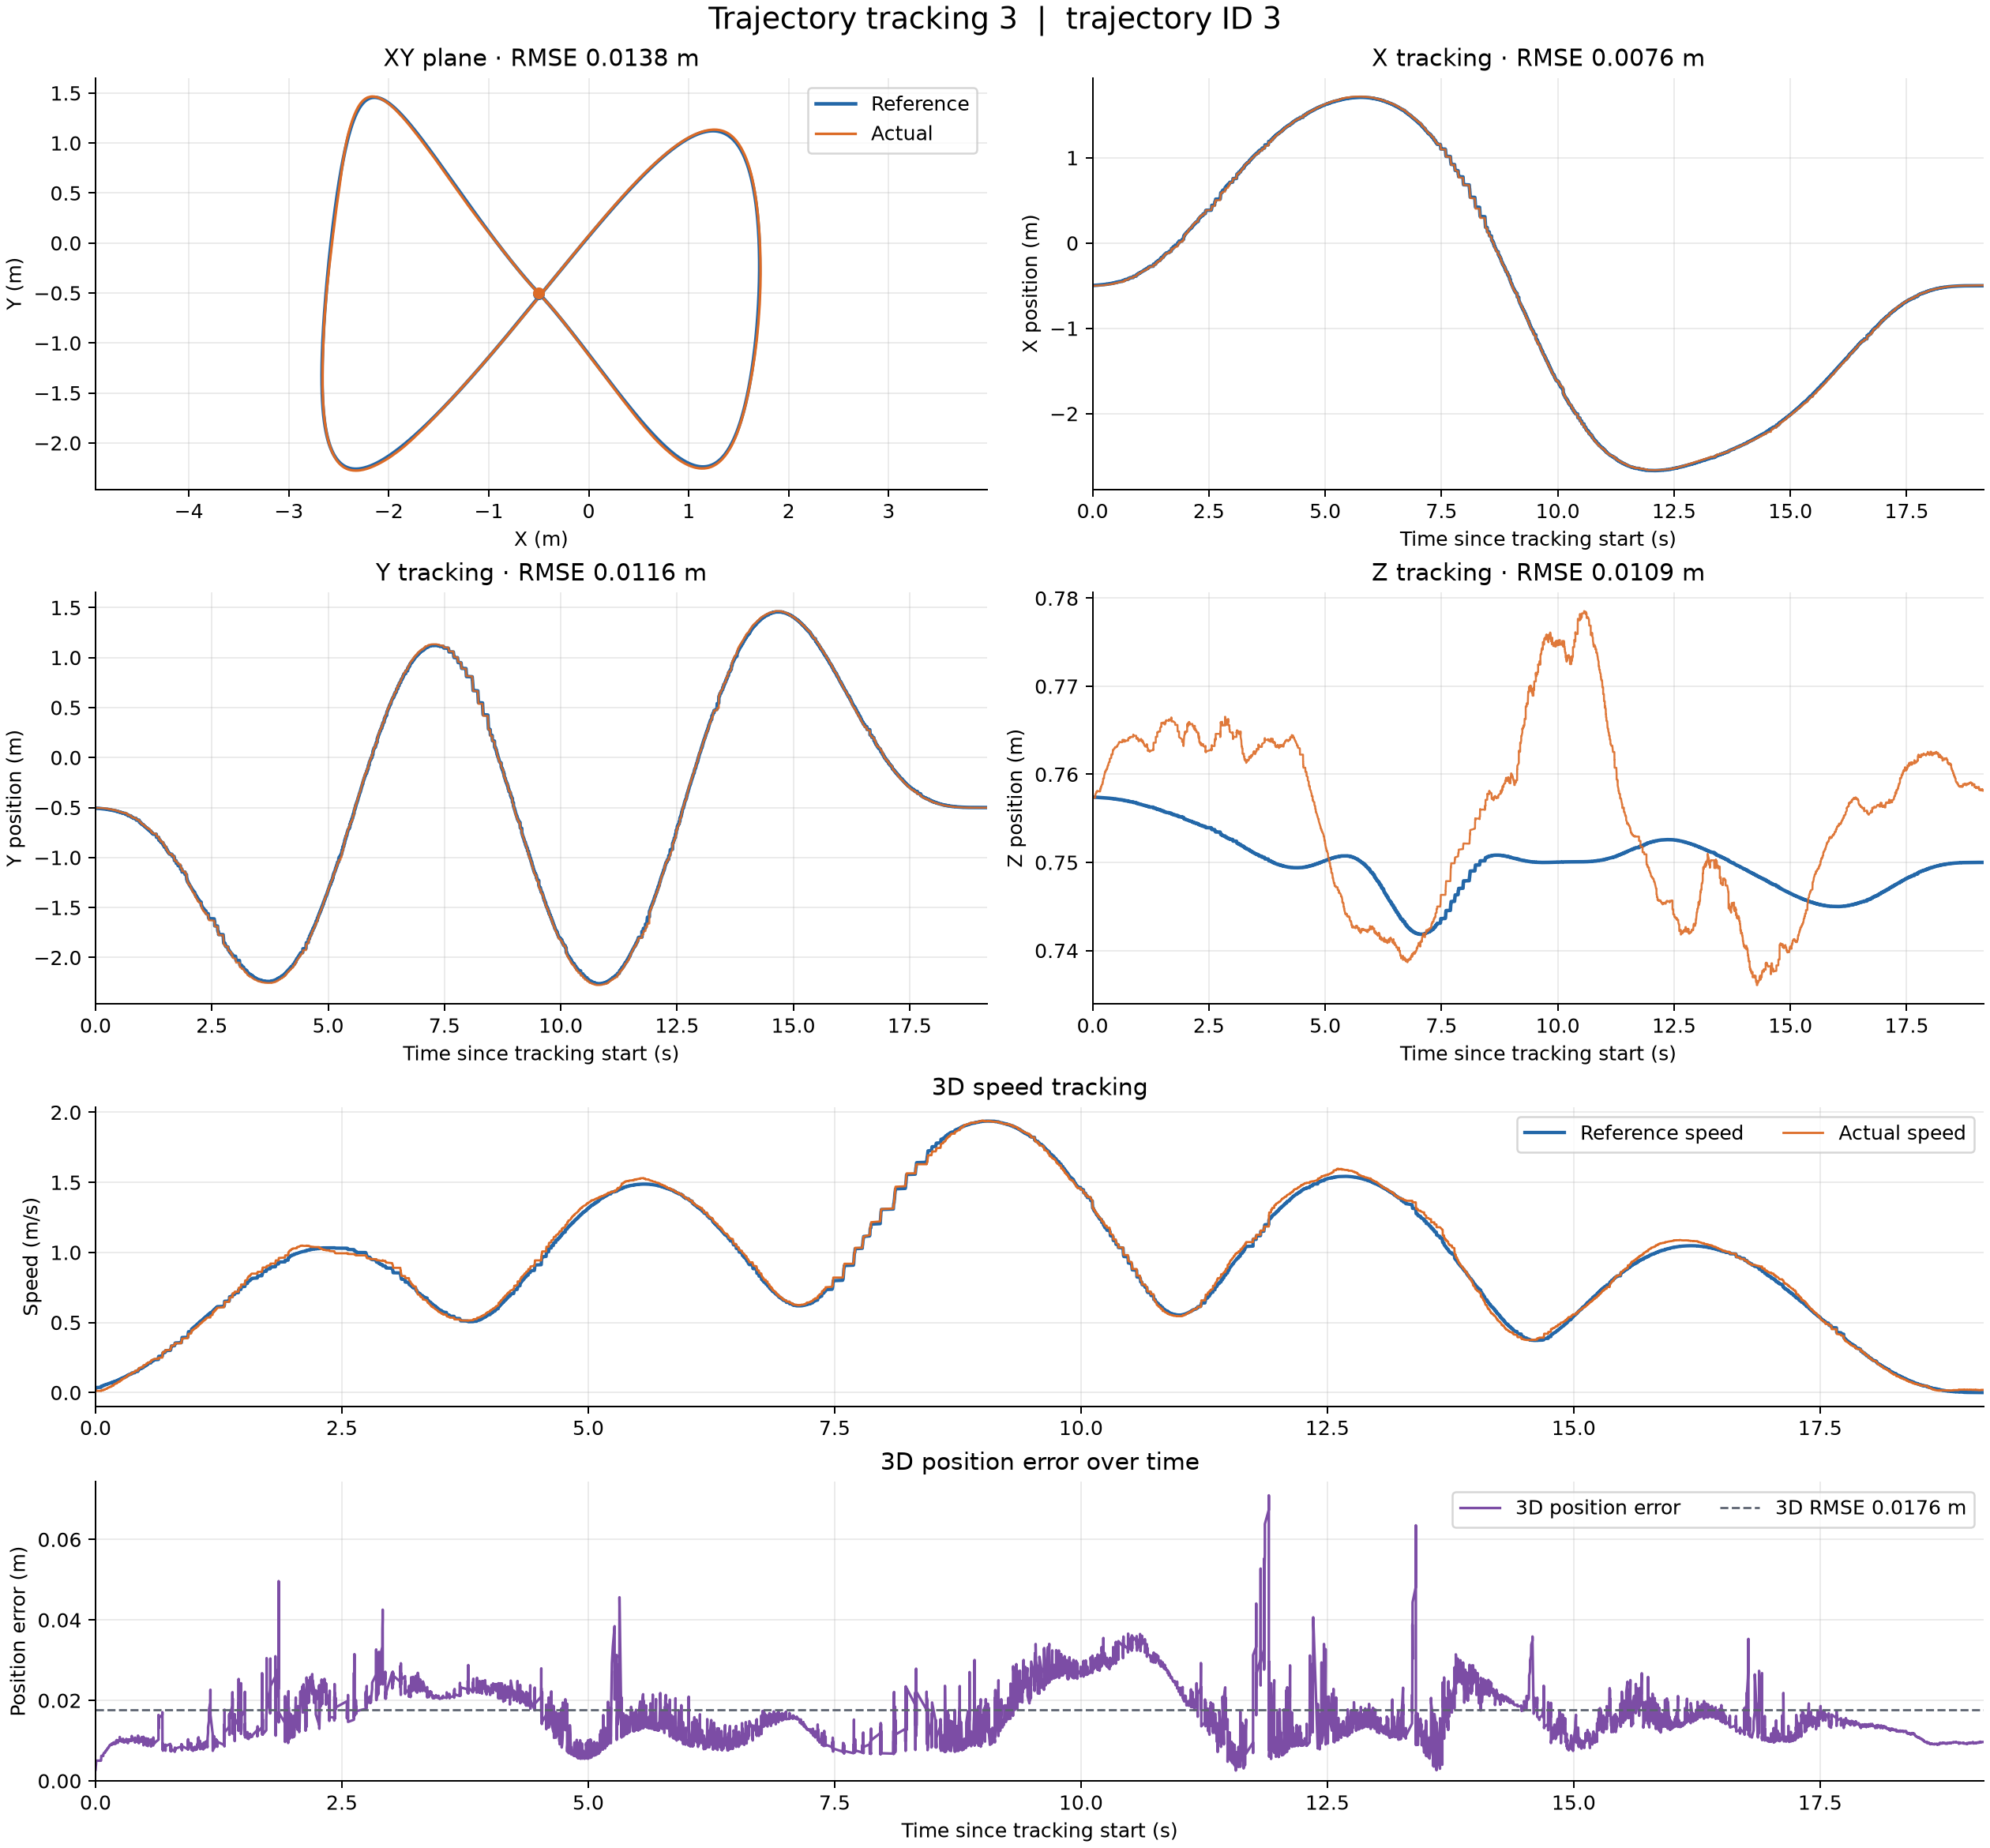

| 次数 / 轨迹 ID | X RMSE (m) | Y RMSE (m) | Z RMSE (m) | XY RMSE (m) | XYZ RMSE (m) | 参考最大速度 (m/s) | 实际最大速度 (m/s) |
|---|---:|---:|---:|---:|---:|---:|---:|
| 1 / 1 | 0.0141 | 0.0188 | 0.0137 | 0.0235 | 0.0272 | 1.956 | 1.951 |
| 2 / 2 | 0.0100 | 0.0130 | 0.0118 | 0.0164 | 0.0202 | 1.894 | 1.897 |
| 3 / 3 | 0.0076 | 0.0116 | 0.0109 | 0.0138 | 0.0176 | 1.937 | 1.941 |

图表和原始数据已保存至：/Users/lzf/Documents/wfzf/8/2026-10-23-11-18-10_tracking


In [27]:
def show_inline(image_path):
    display(Image(filename=str(image_path)))

# on_plot 在每张图保存后立即调用，因此图片会在本单元格中逐张出现。
summaries = tracking.analyze(BAG, OUTPUT, NAMESPACE, on_plot=show_inline)

header = "| 次数 / 轨迹 ID | X RMSE (m) | Y RMSE (m) | Z RMSE (m) | XY RMSE (m) | XYZ RMSE (m) | 参考最大速度 (m/s) | 实际最大速度 (m/s) |"
separator = "|---|---:|---:|---:|---:|---:|---:|---:|"
rows = [
    f"| {s['run']} / {s['trajectory_id']} | {s['rmse_x_m']:.4f} | "
    f"{s['rmse_y_m']:.4f} | {s['rmse_z_m']:.4f} | "
    f"{s['rmse_xy_m']:.4f} | {s['rmse_xyz_m']:.4f} | "
    f"{s['max_reference_speed_m_s']:.3f} | {s['max_actual_speed_m_s']:.3f} |"
    for s in summaries
]
display(Markdown('\n'.join([header, separator, *rows])))
print(f"图表和原始数据已保存至：{OUTPUT}")
